# 05 · Advanced models: XGBoost and LightGBM

In [1]:
import glob, hashlib, json, os, platform, random, re, sys, time, warnings
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

import xgboost as xgb
import lightgbm as lgb

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import ParameterSampler

warnings.filterwarnings("ignore", message=".*eval_set.*")


In [2]:
# settings
DATA_DIR = "fe_outputs"
TARGET = "ClosePrice"
MIN_MONTHS, MAX_MONTHS = 6, 30
SEED = 42
STRICT_CHECKS = True
RUN_MANIFEST_FILE = "run_manifest.json"

random.seed(SEED)
np.random.seed(SEED)

run_log = []

def log_step(step, **info):
    run_log.append({"time": datetime.now().isoformat(timespec="seconds"), "step": step, **info})

# hash of the data files
def file_sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

def window_fingerprint(folder):
    parts = [f"{name}:{file_sha256(Path(folder) / name)}"
             for name in ("features_train.csv", "features_val.csv", "features_test.csv")]
    return hashlib.sha256("|".join(parts).encode()).hexdigest()

environment = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "cpu_count": os.cpu_count(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "xgboost": xgb.__version__,
    "lightgbm": lgb.__version__,
    "matplotlib": matplotlib.__version__,
}
log_step("environment", seed=SEED, data_dir=DATA_DIR, target=TARGET, **{k: v for k, v in environment.items() if k in ("python", "xgboost", "lightgbm")})


In [3]:
target = TARGET

def n_months(path):
    return int(re.search(r"train_(\d+)m", str(path)).group(1))

def metrics(y_true, y_pred):
    ape = np.abs(y_pred - y_true) / y_true
    mse = mean_squared_error(y_true, y_pred)

    return {
        "R2": r2_score(y_true, y_pred),
        "MAPE_%": ape.mean() * 100,
        "MdAPE_%": np.median(ape) * 100,
        "MAE_$": mean_absolute_error(y_true, y_pred),
        "MSE_$2": mse,
        "RMSE_$": np.sqrt(mse),
    }

split_dirs = sorted(
    (d for d in glob.glob(f"{DATA_DIR}/train_*m") if MIN_MONTHS <= n_months(d) <= MAX_MONTHS),
    key=n_months
)
print([n_months(d) for d in split_dirs])
if not split_dirs:
    raise FileNotFoundError(f"no train_<N>m folders in {DATA_DIR!r}")

# no dates as features
EXCLUDE_COLS = ["CloseDate"]
_warned = set()

def load_split(folder):
    train = pd.read_csv(f"{folder}/features_train.csv")
    val = pd.read_csv(f"{folder}/features_val.csv")
    test = pd.read_csv(f"{folder}/features_test.csv")

    banned = [c for c in train.columns
              if c in EXCLUDE_COLS or "date" in c.lower()]
    feats = (train.drop(columns=[target] + banned)
                  .select_dtypes(include="number").columns)
    dropped = [c for c in train.columns if c != target and c not in feats]
    if dropped and tuple(dropped) not in _warned:
        _warned.add(tuple(dropped))
        print("dropped:", dropped)

    X_tr, X_val, X_te = (
        df[feats].replace([np.inf, -np.inf], np.nan) for df in (train, val, test)
    )

    # nans -> train median
    med = X_tr.median()
    X_tr, X_val, X_te = X_tr.fillna(med), X_val.fillna(med), X_te.fillna(med)

    return X_tr, train[target], X_val, val[target], X_te, test[target]


[6, 9, 12, 15, 18, 21, 24, 27]


In [4]:
# names that might be leaky
LEAKAGE_PATTERNS = [
    r"listprice", r"previouslistprice", r"currentprice", r"daysonmarket", r"(^|_)(dom|cdom)($|_)",
    r"pricechange", r"closeprice", r"closedate", r"purchasecontract", r"pendingtimestamp",
    r"offmarket", r"statuschange", r"contingent",
]

audit_rows, fingerprints, test_signature = [], {}, {}

for folder in split_dirs:
    months = n_months(folder)
    fingerprints[months] = window_fingerprint(folder)

    header = {s: pd.read_csv(f"{folder}/features_{s}.csv", nrows=0).columns.tolist()
              for s in ("train", "val", "test")}
    rows, tgt, dates = {}, {}, {}
    for s in ("train", "val", "test"):
        use = [c for c in (target, "CloseDate") if c in header[s]]
        part = pd.read_csv(f"{folder}/features_{s}.csv", usecols=use)
        rows[s] = len(part)
        tgt[s] = part[target] if target in part else pd.Series(dtype=float)
        if "CloseDate" in part:
            dates[s] = pd.to_datetime(part["CloseDate"], errors="coerce")

    problems = []
    if not (header["train"] == header["val"] == header["test"]):
        problems.append("columns differ across train/val/test")
    for s in ("train", "val", "test"):
        if target not in header[s]:
            problems.append(f"{s}: target column {target!r} missing")
        elif tgt[s].isna().any() or (tgt[s] <= 0).any():
            problems.append(f"{s}: missing or non-positive {target}")
    if len(dates) == 3 and not (dates["train"].max() < dates["val"].min()
                                and dates["val"].max() < dates["test"].min()):
        problems.append("splits are not in chronological order (train < val < test)")
    test_signature[months] = (rows["test"], round(float(tgt["test"].sum()), 2))

    used = [c for c in header["train"]
            if c != target and c not in EXCLUDE_COLS and "date" not in c.lower()]
    flagged = [c for c in used if any(re.search(p, c.lower()) for p in LEAKAGE_PATTERNS)]

    audit_rows.append({
        "n_months": months,
        "train_rows": rows["train"], "val_rows": rows["val"], "test_rows": rows["test"],
        "n_columns": len(header["train"]),
        "train_end": dates["train"].max().date() if dates else None,
        "val_start": dates["val"].min().date() if dates else None,
        "val_end": dates["val"].max().date() if dates else None,
        "test_start": dates["test"].min().date() if dates else None,
        "test_end": dates["test"].max().date() if dates else None,
        "fingerprint": fingerprints[months][:12],
        "leakage_name_flags": ", ".join(flagged),
        "problems": "; ".join(problems),
    })

data_audit = pd.DataFrame(audit_rows)

if len(set(test_signature.values())) > 1:
    msg = "test month differs across windows"
    data_audit["problems"] = data_audit["problems"].where(data_audit["problems"] == "", data_audit["problems"] + "; ") + msg

n_problems = int((data_audit["problems"] != "").sum())
n_flagged = int((data_audit["leakage_name_flags"] != "").sum())
log_step("input checks", windows=len(data_audit), windows_with_problems=n_problems,
         windows_with_leakage_name_flags=n_flagged)

# stop if something's wrong
if n_problems and STRICT_CHECKS:
    raise ValueError("input checks failed\n" + data_audit[["n_months", "problems"]].to_string())
if n_flagged:
    print("check these columns:")
    print(data_audit.loc[data_audit["leakage_name_flags"] != "", ["n_months", "leakage_name_flags"]].to_string())

data_audit


,n_months,train_rows,val_rows,test_rows,n_columns,train_end,val_start,val_end,test_start,test_end,fingerprint,leakage_name_flags,problems
0,6,64566,12748,11352,83,2026-06-30,2026-07-01,2026-07-31,2026-08-01,2026-08-31,a1e72438292e,,
1,9,96739,12748,11352,83,2026-06-30,2026-07-01,2026-07-31,2026-08-01,2026-08-31,6f358c7da66f,,
2,12,131702,12748,11352,83,2026-06-30,2026-07-01,2026-07-31,2026-08-01,2026-08-31,f96813c8d84c,,
3,15,166979,12748,11352,83,2026-06-30,2026-07-01,2026-07-31,2026-08-01,2026-08-31,15322bc99183,,
4,18,194532,12748,11352,83,2026-06-30,2026-07-01,2026-07-31,2026-08-01,2026-08-31,fe91cfae6253,,
5,21,228140,12748,11352,83,2026-06-30,2026-07-01,2026-07-31,2026-08-01,2026-08-31,c37cf5d7cbd1,,
6,24,264762,12748,11352,83,2026-06-30,2026-07-01,2026-07-31,2026-08-01,2026-08-31,8a04a62964b9,,
7,27,303805,12748,11352,83,2026-06-30,2026-07-01,2026-07-31,2026-08-01,2026-08-31,dc5a23234ecf,,


## Tuning

In [5]:
# auto: reuse saved params, tune: redo search, best_only: never tune
TUNING_MODE = "auto"

BEST_PARAMS_FILE = "gbm_best_params.json"
RESULTS_FILE = "gbm_results.csv"
TUNING_RESULTS_FILE = "gbm_tuning_results.csv"

TUNE_MONTHS = 24
N_ITER = 10
MAX_TREES = 1500
EARLY_STOP = 100

# search space
param_spaces = {
    "LightGBM": {
        "num_leaves": [31, 63, 127, 255],
        "learning_rate": [0.05, 0.1],
        "min_child_samples": [10, 20, 50],
        "subsample": [0.7, 0.8, 1.0],
        "colsample_bytree": [0.5, 0.7, 0.9],
        "reg_lambda": [0, 1, 10],
        "log_target": [False, True],
    },
    "XGBoost": {
        "max_depth": [4, 6, 8, 10],
        "learning_rate": [0.05, 0.1],
        "min_child_weight": [1, 5, 10],
        "subsample": [0.7, 0.8, 1.0],
        "colsample_bytree": [0.5, 0.7, 0.9],
        "reg_lambda": [1, 10],
        "log_target": [False, True],
    },
}

if TUNING_MODE not in {"auto", "tune", "best_only"}:
    raise ValueError("TUNING_MODE should be auto, tune or best_only")
if TUNE_MONTHS not in fingerprints:
    raise ValueError(f"TUNE_MONTHS {TUNE_MONTHS} not in {sorted(fingerprints)}")

# predicts in dollars even with log target
class GBM:
    def __init__(self, model, log_target, best_iteration):
        self.model = model
        self.log_target = log_target
        self.best_iteration = best_iteration

    def predict(self, X):
        pred = self.model.predict(X)
        return np.exp(pred) if self.log_target else pred

def fit_gbm(name, params, X_tr, y_tr, X_val, y_val):
    params = dict(params)
    log_target = params.pop("log_target")
    y_fit, y_eval = (np.log(y_tr), np.log(y_val)) if log_target else (y_tr, y_val)

    if name == "LightGBM":
        model = lgb.LGBMRegressor(
            n_estimators=MAX_TREES, subsample_freq=1,
            random_state=SEED, n_jobs=-1, verbose=-1, **params
        )
        model.fit(X_tr, y_fit, eval_set=[(X_val, y_eval)],
                  callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
        best_iter = model.best_iteration_
    else:
        model = xgb.XGBRegressor(
            n_estimators=MAX_TREES, tree_method="hist",
            early_stopping_rounds=EARLY_STOP,
            random_state=SEED, n_jobs=-1, **params
        )
        model.fit(X_tr, y_fit, eval_set=[(X_val, y_eval)], verbose=False)
        best_iter = model.best_iteration + 1

    return GBM(model, log_target, best_iter)


In [6]:
saved_params, saved_meta = {}, {}
if TUNING_MODE != "tune" and Path(BEST_PARAMS_FILE).exists():
    saved_params = json.loads(Path(BEST_PARAMS_FILE).read_text())
    saved_meta = saved_params.pop("_meta", {})
    if saved_meta.get("data_fingerprint") != fingerprints[TUNE_MONTHS]:
        msg = f"{BEST_PARAMS_FILE} is from different data."
        if TUNING_MODE == "best_only":
            raise ValueError(msg)
        print(msg, "re-tuning")
        saved_params, saved_meta = {}, {}

# params from my run, used only if your data matches
EMBEDDED_PARAMS = {
    "data_fingerprint": "8a04a62964b990ceccc99a45e07bd0ffa564c855991d7af15929f3452f53dd2b",
    "tune_months": 24,
    "params": {
        "LightGBM": {
            "subsample": 1.0,
            "reg_lambda": 1,
            "num_leaves": 255,
            "min_child_samples": 50,
            "log_target": True,
            "learning_rate": 0.1,
            "colsample_bytree": 0.7
        },
        "XGBoost": {
            "subsample": 1.0,
            "reg_lambda": 10,
            "min_child_weight": 1,
            "max_depth": 10,
            "log_target": False,
            "learning_rate": 0.05,
            "colsample_bytree": 0.9
        }
    }
}

if not saved_params and TUNING_MODE != "tune" and EMBEDDED_PARAMS["data_fingerprint"] == fingerprints[TUNE_MONTHS]:
    saved_params = {f"{TUNE_MONTHS}m_{name}": p for name, p in EMBEDDED_PARAMS["params"].items()}
    print("using embedded params")

meta_now = {
    "data_fingerprint": fingerprints[TUNE_MONTHS], "tune_months": TUNE_MONTHS, "seed": SEED,
    "n_iter": N_ITER, "max_trees": MAX_TREES, "early_stop": EARLY_STOP,
    "selection_metric": "validation MdAPE", "created": datetime.now().isoformat(timespec="seconds"),
    "xgboost": xgb.__version__, "lightgbm": lgb.__version__,
}
tuned_now = []

tuning_rows = []

X_tr, y_tr, X_val, y_val, X_te, y_te = load_split(f"{DATA_DIR}/train_{TUNE_MONTHS}m")

for name in param_spaces:
    key = f"{TUNE_MONTHS}m_{name}"

    if TUNING_MODE == "best_only" and key not in saved_params:
        raise FileNotFoundError(
            f"no saved params for {key}"
        )
    if TUNING_MODE != "tune" and key in saved_params:
        print(f"{name}: saved params {saved_params[key]}")
        continue

    # random search, pick best on val
    best_score = np.inf
    candidates = ParameterSampler(param_spaces[name], n_iter=N_ITER, random_state=SEED)
    for i, params in enumerate(candidates, 1):
        params = dict(params)
        t0 = time.time()
        candidate = fit_gbm(name, params, X_tr, y_tr, X_val, y_val)
        scores = metrics(y_val, candidate.predict(X_val))
        tuning_rows.append({
            "model": name,
            "n_train_months": TUNE_MONTHS,
            "params": str(params),
            "log_target": params["log_target"],
            "best_iteration": candidate.best_iteration,
            "val_R2": scores["R2"],
            "val_MAPE_%": scores["MAPE_%"],
            "val_MdAPE_%": scores["MdAPE_%"],
            "fit_seconds": time.time() - t0,
        })
        print(f"{name} {i}/{N_ITER}  val MdAPE {scores['MdAPE_%']:.3f}  R2 {scores['R2']:.4f}  "
              f"trees {candidate.best_iteration}  {time.time() - t0:.0f}s")
        if scores["MdAPE_%"] < best_score:
            best_score, best_params = scores["MdAPE_%"], params
        del candidate

    saved_params[key] = best_params
    tuned_now.append(name)
    Path(BEST_PARAMS_FILE).write_text(json.dumps({**saved_params, "_meta": meta_now}, indent=2))
    print(f"{name} best: {best_score:.3f} {best_params}\n")

if tuning_rows:
    new_tuning = pd.DataFrame(tuning_rows)
    if TUNING_MODE == "auto" and Path(TUNING_RESULTS_FILE).exists():
        old = pd.read_csv(TUNING_RESULTS_FILE)
        old = old[~old["model"].isin(new_tuning["model"].unique())]
        new_tuning = pd.concat([old, new_tuning], ignore_index=True)
    new_tuning.to_csv(TUNING_RESULTS_FILE, index=False)

tuning_results = pd.read_csv(TUNING_RESULTS_FILE) if Path(TUNING_RESULTS_FILE).exists() else pd.DataFrame()
log_step("hyperparameters", tune_months=TUNE_MONTHS, tuned_now=tuned_now or "none",
         **{f"best_{n}": saved_params[f"{TUNE_MONTHS}m_{n}"] for n in param_spaces})


using embedded params
dropped: ['CloseDate']
LightGBM: saved params {'subsample': 1.0, 'reg_lambda': 1, 'num_leaves': 255, 'min_child_samples': 50, 'log_target': True, 'learning_rate': 0.1, 'colsample_bytree': 0.7}
XGBoost: saved params {'subsample': 1.0, 'reg_lambda': 10, 'min_child_weight': 1, 'max_depth': 10, 'log_target': False, 'learning_rate': 0.05, 'colsample_bytree': 0.9}


In [7]:
if tuning_results.empty:
    print("no tuning log")
else:
    display(tuning_results
        .sort_values(["model", "val_MdAPE_%"])
        .groupby("model").head(5)
        [["model", "log_target", "best_iteration", "val_R2", "val_MAPE_%", "val_MdAPE_%", "params"]]
        .round(4))


no tuning log


In [8]:
if tuning_results.empty:
    print("no tuning log")
else:
    display(tuning_results
        .groupby(["model", "log_target"])[["val_R2", "val_MAPE_%", "val_MdAPE_%"]]
        .mean()
        .round(4))


no tuning log


In [9]:
# skip windows we already did
REUSE_SAVED_RESULTS = True

store = {}
if REUSE_SAVED_RESULTS and Path(RESULTS_FILE).exists():
    store = {(r["model"], r["n_train_months"]): r
             for r in pd.read_csv(RESULTS_FILE).to_dict("records")}

fitted_now, reused_now = [], []
best_models = {}

for folder in split_dirs:
    months = n_months(folder)

    todo = []
    for name in param_spaces:
        best_params = saved_params[f"{TUNE_MONTHS}m_{name}"]
        old = store.get((name, months))
        if old is not None and months != TUNE_MONTHS and old["best_params"] == str(best_params) \
                and old.get("data_fingerprint") == fingerprints[months]:
            print(f"{months}m {name}: reused")
            reused_now.append((name, months))
        else:
            todo.append(name)
    if not todo:
        continue

    X_tr, y_tr, X_val, y_val, X_te, y_te = load_split(folder)

    for name in todo:
        best_params = saved_params[f"{TUNE_MONTHS}m_{name}"]

        t0 = time.time()
        model = fit_gbm(name, best_params, X_tr, y_tr, X_val, y_val)
        fit_seconds = time.time() - t0
        val_pred = model.predict(X_val)
        pred = model.predict(X_te)

        if months == TUNE_MONTHS:
            best_models[name] = model

        store[(name, months)] = {
            "model": name,
            "n_train_months": months,
            "n_train_rows": len(X_tr),
            "data_fingerprint": fingerprints[months],
            "seed": SEED,
            "best_params": str(best_params),
            "best_iteration": model.best_iteration,
            "fit_seconds": fit_seconds,
            **{f"val_{k}": v for k, v in metrics(y_val, val_pred).items()},
            "val_neg_preds": int((val_pred <= 0).sum()),
            **{f"test_{k}": v for k, v in metrics(y_te, pred).items()},
            "neg_preds": int((pred <= 0).sum()),
        }
        fitted_now.append((name, months))
        row = store[(name, months)]
        print(f"{months}m {name}: test R2 {row['test_R2']:.4f}, MdAPE {row['test_MdAPE_%']:.3f}")
        pd.DataFrame(store.values()).to_csv(RESULTS_FILE, index=False)

results = pd.DataFrame(
    [store[(name, n_months(f))] for f in split_dirs for name in param_spaces]
)
log_step("train windows", fitted=len(fitted_now), reused=len(reused_now), results_file=RESULTS_FILE)
display(results.drop(columns=["best_params", "data_fingerprint"]))


6m LightGBM: reused
6m XGBoost: reused
9m LightGBM: reused
9m XGBoost: reused
12m LightGBM: reused
12m XGBoost: reused
15m LightGBM: reused
15m XGBoost: reused
18m LightGBM: reused
18m XGBoost: reused
21m LightGBM: reused
21m XGBoost: reused
24m LightGBM: test R2 0.8697, MdAPE 7.351
24m XGBoost: test R2 0.8715, MdAPE 7.451
27m LightGBM: reused
27m XGBoost: reused


,model,n_train_months,n_train_rows,seed,best_iteration,fit_seconds,val_R2,val_MAPE_%,val_MdAPE_%,val_MAE_$,val_MSE_$2,val_RMSE_$,val_neg_preds,test_R2,test_MAPE_%,test_MdAPE_%,test_MAE_$,test_MSE_$2,test_RMSE_$,neg_preds
0,LightGBM,6,64566,42,222,28.534375,0.819720,12.062053,7.588418,173332.922934,3.611357e+11,600945.634371,0,0.858119,12.061266,7.810997,175646.017435,2.817571e+11,530807.986895,0
1,XGBoost,6,64566,42,1487,52.739548,0.767751,12.495947,7.572364,179536.411413,4.652379e+11,682083.463686,0,0.830402,12.482714,7.822269,181709.722609,3.367992e+11,580344.067657,0
2,LightGBM,9,96739,42,286,13.550051,0.824067,11.793628,7.405266,169398.952731,3.524264e+11,593655.122429,0,0.862633,11.638430,7.679719,170777.814955,2.727942e+11,522297.039160,0
3,XGBoost,9,96739,42,1483,69.088804,0.811799,12.451759,7.433425,175519.813631,3.770022e+11,614005.054022,0,0.846279,12.349480,7.754027,176692.435100,3.052702e+11,552512.647553,0
4,LightGBM,12,131702,42,375,15.217726,0.835637,11.548763,7.270283,164967.694951,3.292505e+11,573803.500641,0,0.864507,11.501575,7.575090,168388.008288,2.690712e+11,518720.715627,0
5,XGBoost,12,131702,42,1379,56.403383,0.796972,11.963234,7.212420,171280.425883,4.067027e+11,637732.475543,0,0.859949,12.022389,7.573250,171775.411167,2.781231e+11,527373.783689,0
6,LightGBM,15,166979,42,406,23.792534,0.831114,11.408487,7.370734,165619.695291,3.383101e+11,581644.345628,0,0.875295,11.209219,7.620577,163923.695466,2.476484e+11,497642.885119,0
7,XGBoost,15,166979,42,1498,79.642646,0.812770,11.729067,7.234942,167190.219083,3.750578e+11,612419.623070,0,0.867487,11.628379,7.536474,168251.002713,2.631544e+11,512985.748412,0
8,LightGBM,18,194532,42,404,19.012803,0.834598,11.302068,7.226856,164088.723385,3.313308e+11,575613.389371,0,0.870777,11.126160,7.485056,163508.751450,2.566206e+11,506577.335825,0
9,XGBoost,18,194532,42,1497,89.675908,0.817430,11.681250,7.105897,167401.054637,3.657212e+11,604748.833124,0,0.864545,11.590388,7.476706,167760.827061,2.689962e+11,518648.483202,0


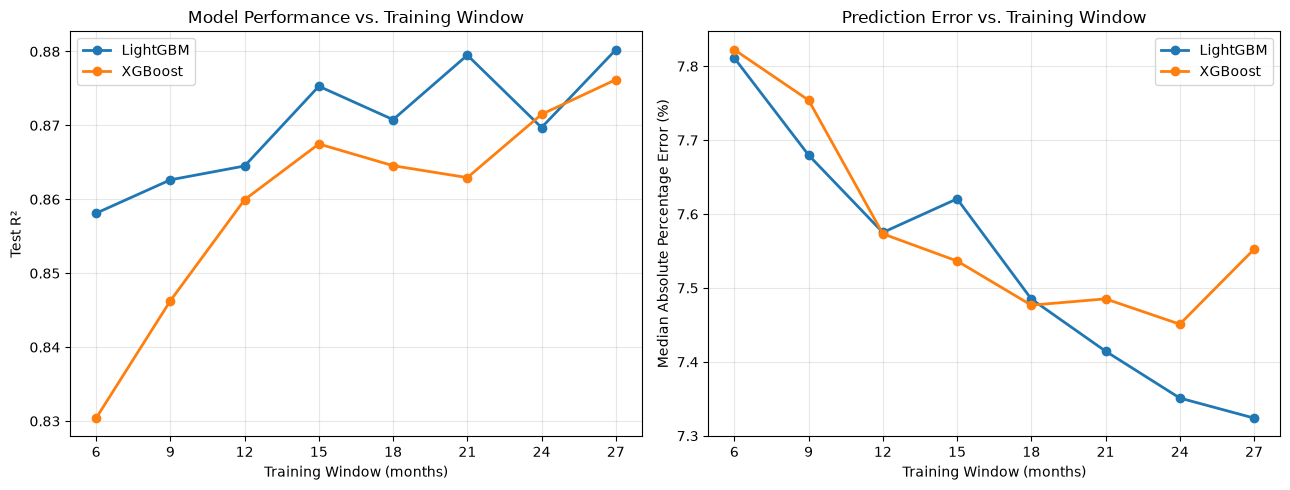

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in results.groupby("model"):

    group = group.sort_values("n_train_months")

    axes[0].plot(
        group["n_train_months"],
        group["test_R2"],
        marker="o",
        linewidth=2,
        label=name
    )

    axes[1].plot(
        group["n_train_months"],
        group["test_MdAPE_%"],
        marker="o",
        linewidth=2,
        label=name
    )

axes[0].set(
    xlabel="Training Window (months)",
    ylabel="Test R²",
    title="Model Performance vs. Training Window"
)

axes[1].set(
    xlabel="Training Window (months)",
    ylabel="Median Absolute Percentage Error (%)",
    title="Prediction Error vs. Training Window"
)

for ax in axes:
    ax.set_xticks(sorted(results["n_train_months"].unique()))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


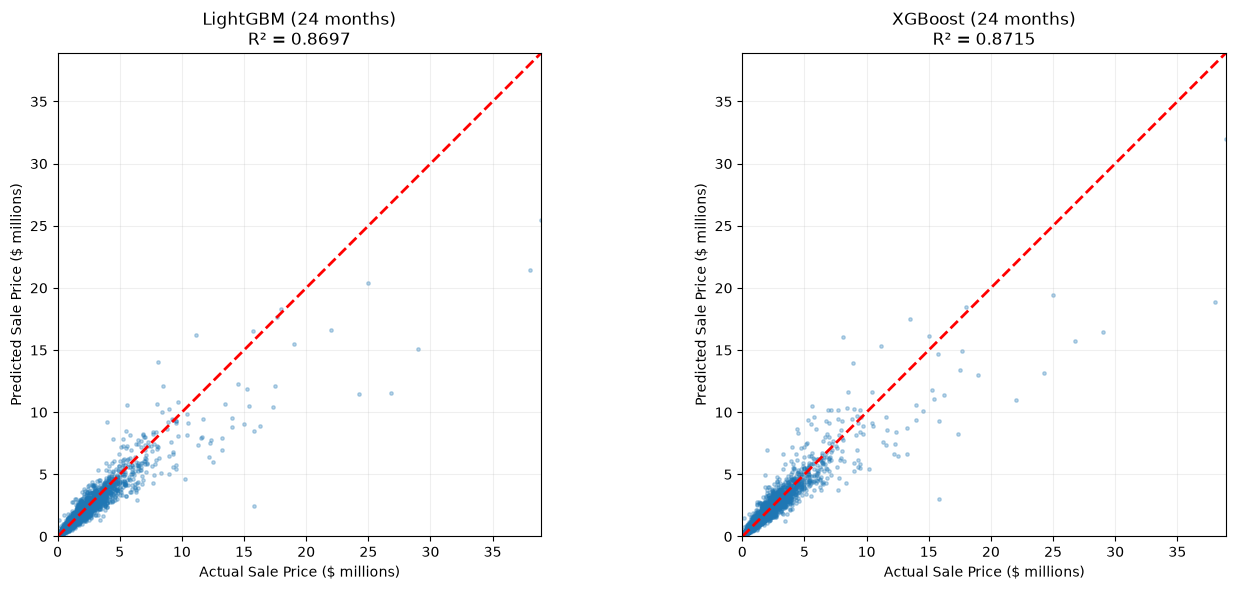

R2     MAPE_%   MdAPE_%          MAE_$  \
LightGBM validation  0.846005  11.096971  7.052065  160084.069825   
         test        0.869707  10.996615  7.351068  161411.395538   
XGBoost  validation  0.823563  11.694157  7.077160  164362.476135   
         test        0.871492  11.606972  7.451004  165119.637987   

                           MSE_$2         RMSE_$  
LightGBM validation  3.084801e+11  555409.830500  
         test        2.587462e+11  508671.009425  
XGBoost  validation  3.534356e+11  594504.477796  
         test        2.552001e+11  505173.381447

In [11]:
MONTHS = TUNE_MONTHS

folder = f"{DATA_DIR}/train_{MONTHS}m"

X_tr, y_tr, X_val, y_val, X_te, y_te = load_split(folder)
models = best_models

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, model) in zip(axes, models.items()):

    pred = model.predict(X_te)

    actual_millions = y_te / 1_000_000
    predicted_millions = pred / 1_000_000

    ax.scatter(
        actual_millions,
        predicted_millions,
        s=6,
        alpha=0.3
    )

    limit = max(
        actual_millions.max(),
        predicted_millions.max()
    )

    ax.plot(
        [0, limit],
        [0, limit],
        "r--",
        linewidth=2,
    )

    ax.set_xlabel("Actual Sale Price ($ millions)")
    ax.set_ylabel("Predicted Sale Price ($ millions)")

    ax.set_title(
        f"{name} ({MONTHS} months)\n"
        f"R² = {r2_score(y_te, pred):.4f}"
    )

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_aspect("equal", adjustable="box")

    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

pd.concat({
    name: pd.DataFrame({
        "validation": metrics(y_val, model.predict(X_val)),
        "test": metrics(y_te, model.predict(X_te)),
    }).T
    for name, model in models.items()
})


## Comparison

In [12]:
frames = [results]
for label, path in [("baseline", "baseline_results.csv"), ("tree/forest", "tree_forest_results.csv")]:
    if Path(path).exists():
        frames.insert(0, pd.read_csv(path))
    else:
        print(f"{path} not found, skipping")

keep = (["model", "n_train_months", "n_train_rows"]
        + [c for c in results.columns if c.startswith(("val_", "test_"))] + ["neg_preds"])
all_results = pd.concat(frames, ignore_index=True).reindex(columns=keep)

order = [m for m in ["LinearRegression", "DecisionTree", "RandomForest", "XGBoost", "LightGBM"]
         if m in set(all_results["model"])]
cols = ["val_R2", "val_MdAPE_%", "test_R2", "test_MAPE_%", "test_MdAPE_%", "test_MAE_$", "test_RMSE_$", "neg_preds"]

comparison = (all_results[all_results["n_train_months"] == TUNE_MONTHS]
              .set_index("model")[cols].loc[order])

for ref, label in [("LinearRegression", "LR"), ("RandomForest", "RF")]:
    if ref in comparison.index:
        comparison[f"MdAPE_gain_vs_{label}_%"] = (1 - comparison["test_MdAPE_%"] / comparison.loc[ref, "test_MdAPE_%"]) * 100
comparison["neg_preds"] = comparison["neg_preds"].astype("Int64")

selected = comparison["val_MdAPE_%"].idxmin()
log_step("model comparison", window_months=TUNE_MONTHS, models=len(comparison), selected_by="validation MdAPE",
         selected_model=selected, test_R2=round(float(comparison.loc[selected, "test_R2"]), 4),
         test_MdAPE_pct=round(float(comparison.loc[selected, "test_MdAPE_%"]), 3))
comparison.round(4)


,val_R2,val_MdAPE_%,test_R2,test_MAPE_%,test_MdAPE_%,test_MAE_$,test_RMSE_$,neg_preds,MdAPE_gain_vs_LR_%,MdAPE_gain_vs_RF_%
model,,,,,,,,,,
LinearRegression,0.7844,13.0453,0.8189,18.7913,13.4443,240398.0491,599638.3455,1,0.0000,-59.0680
DecisionTree,0.8085,11.6970,0.7948,17.2556,11.8243,227367.5009,638348.2641,0,12.0494,-39.9013
RandomForest,0.8368,8.2159,0.8691,13.1079,8.4519,182493.9499,509796.1358,0,37.1338,0.0000
XGBoost,0.8236,7.0772,0.8715,11.6070,7.4510,165119.6380,505173.3814,0,44.5785,11.8422
LightGBM,0.8460,7.0521,0.8697,10.9966,7.3511,161411.3955,508671.0094,0,45.3219,13.0246


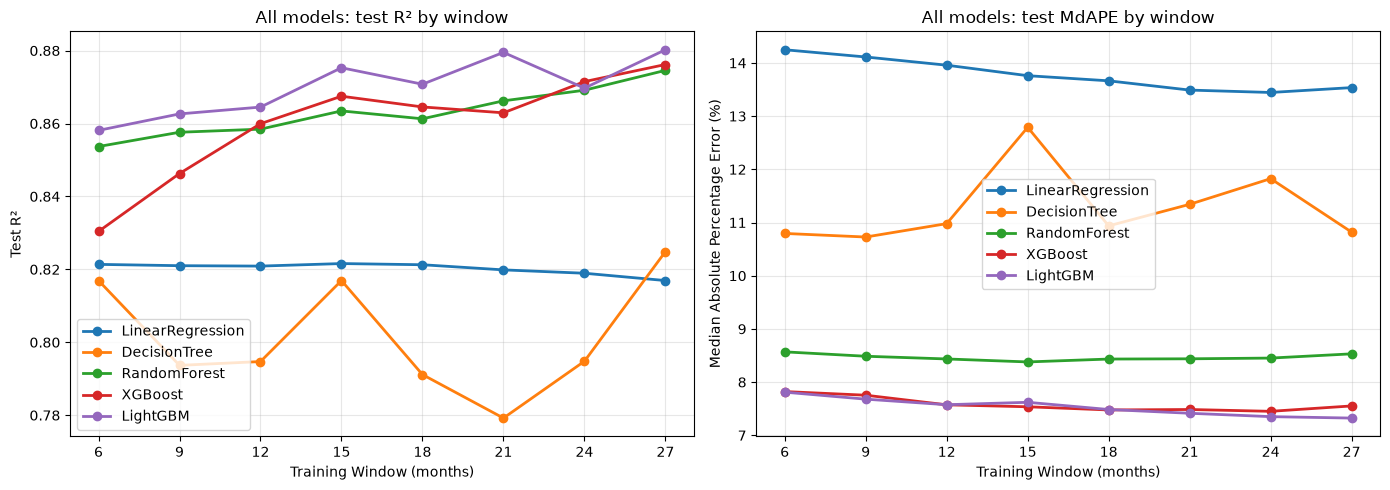

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name in order:
    g = all_results[all_results["model"] == name].sort_values("n_train_months")
    axes[0].plot(g["n_train_months"], g["test_R2"], marker="o", linewidth=2, label=name)
    axes[1].plot(g["n_train_months"], g["test_MdAPE_%"], marker="o", linewidth=2, label=name)

axes[0].set(xlabel="Training Window (months)", ylabel="Test R²", title="All models: test R² by window")
axes[1].set(xlabel="Training Window (months)", ylabel="Median Absolute Percentage Error (%)",
            title="All models: test MdAPE by window")
for ax in axes:
    ax.set_xticks(sorted(all_results["n_train_months"].unique()))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [14]:
lr = LinearRegression().fit(X_tr, y_tr)
ape = {"LinearRegression": np.abs(lr.predict(X_te) - y_te).to_numpy() / y_te.to_numpy()}
for name, model in models.items():
    ape[name] = np.abs(model.predict(X_te) - y_te).to_numpy() / y_te.to_numpy()

# resample the test set to see if the gap is real
rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(y_te), size=(1000, len(y_te)))

def paired_diff(a, b):
    d = np.array([np.median(ape[a][i]) - np.median(ape[b][i]) for i in idx]) * 100
    lo, hi = np.percentile(d, [2.5, 97.5])
    return {"model_a": a, "model_b": b, "MdAPE_diff_pp": d.mean(), "ci_low": lo, "ci_high": hi,
            "excludes_zero": bool(lo > 0 or hi < 0)}

pd.DataFrame([paired_diff("LightGBM", "LinearRegression"),
              paired_diff("XGBoost", "LinearRegression"),
              paired_diff("LightGBM", "XGBoost")]).round(3)


,model_a,model_b,MdAPE_diff_pp,ci_low,ci_high,excludes_zero
0,LightGBM,LinearRegression,-6.074,-6.384,-5.771,True
1,XGBoost,LinearRegression,-5.980,-6.265,-5.679,True
2,LightGBM,XGBoost,-0.094,-0.238,0.038,False


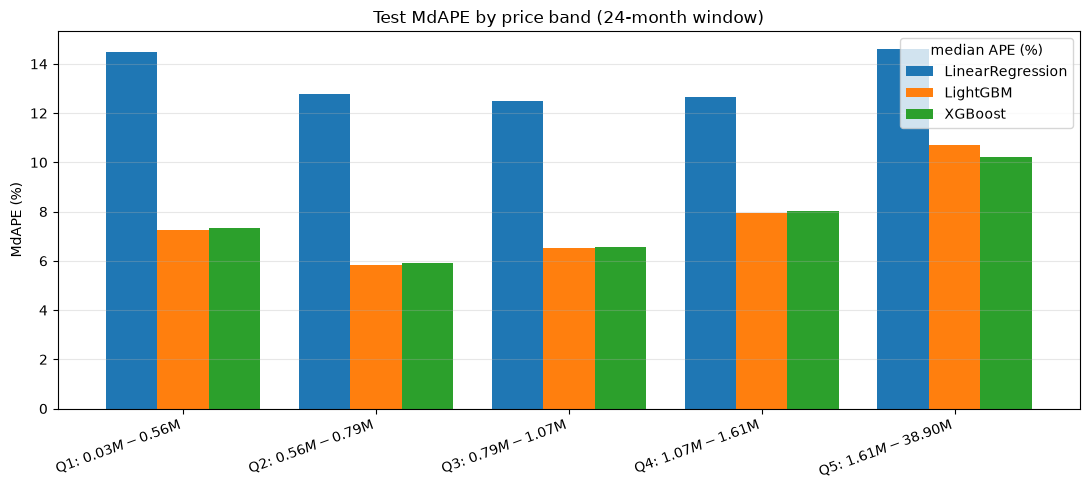

median APE (%),LinearRegression,LightGBM,XGBoost
Q1: $0.03M-$0.56M,14.49,7.24,7.34
Q2: $0.56M-$0.79M,12.78,5.82,5.89
Q3: $0.79M-$1.07M,12.51,6.53,6.55
Q4: $1.07M-$1.61M,12.67,7.94,8.02
Q5: $1.61M-$38.90M,14.59,10.73,10.23


In [15]:
edges = np.quantile(y_te, np.linspace(0, 1, 6))
band = np.clip(np.searchsorted(edges, y_te.to_numpy(), side="right") - 1, 0, 4)
band_labels = [f"Q{i+1}: ${edges[i]/1e6:.2f}M-${edges[i+1]/1e6:.2f}M" for i in range(5)]

band_table = pd.DataFrame({
    name: pd.Series(a * 100).groupby(band).median() for name, a in ape.items()
})
band_table.index = band_labels
band_table.columns.name = "median APE (%)"

ax = band_table.plot.bar(figsize=(11, 5), width=0.8)
ax.set(ylabel="MdAPE (%)", title=f"Test MdAPE by price band ({MONTHS}-month window)")
ax.grid(alpha=0.3, axis="y")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

band_table.round(2)


## Feature importance

In [16]:
gain = {
    "LightGBM": pd.Series(
        models["LightGBM"].model.booster_.feature_importance(importance_type="gain"),
        index=X_tr.columns),
    "XGBoost": pd.Series(
        models["XGBoost"].model.get_booster().get_score(importance_type="gain")
    ).reindex(X_tr.columns).fillna(0),
}

importances = pd.DataFrame(gain)
importances = (importances / importances.sum()).sort_values("LightGBM", ascending=False)

importances.head(15)


,LightGBM,XGBoost
est_value_area,0.702622,0.309012
PostalCode_cat_te,0.138548,0.008398
log_est_value_area,0.043156,0.436629
log_living_area,0.022342,0.004586
City_te,0.008249,0.004309
zip_med_ppsf_12m,0.006449,0.003835
MLSAreaMajor_te,0.005770,0.009293
living_to_lot_ratio,0.004996,0.002912
Longitude,0.004772,0.005142
LotSizeSquareFeet,0.004755,0.002659


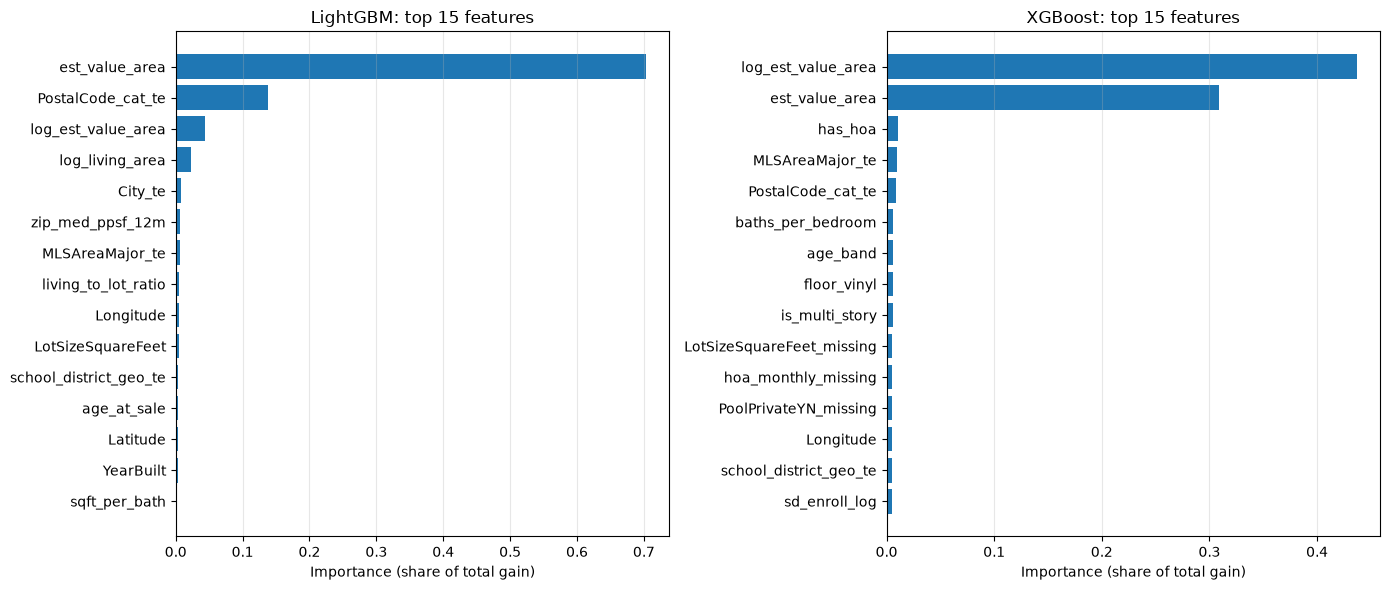

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, name in zip(axes, importances.columns):
    top = importances[name].sort_values(ascending=False).head(15).iloc[::-1]
    ax.barh(top.index, top.values, color="tab:blue")
    ax.set(xlabel="Importance (share of total gain)", title=f"{name}: top 15 features")
    ax.grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.show()
